<a href="https://colab.research.google.com/github/UH-HACKATHON-TEAMN/Hackathon-Town-C/blob/main/lokesh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES AND LOAD DATA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Google Colab: upload both CSV files
from google.colab import files

uploaded = files.upload()

train_df = pd.read_csv("dataset_C_training.csv")
test_df = pd.read_csv("dataset_C_testing.csv")

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Saving dataset_C_testing.csv to dataset_C_testing.csv
Saving dataset_C_training.csv to dataset_C_training.csv
Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance      

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0


,Missing Count,Missing Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


Duplicate rows: 0

Target distribution:
covid_vaccine
0    3202
1    1554
Name: count, dtype: int64


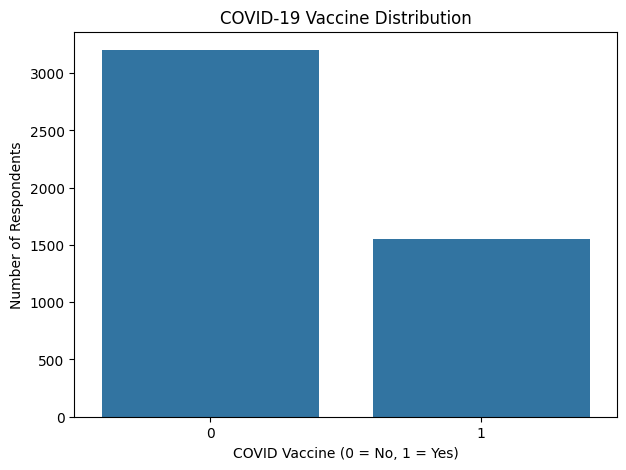

covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


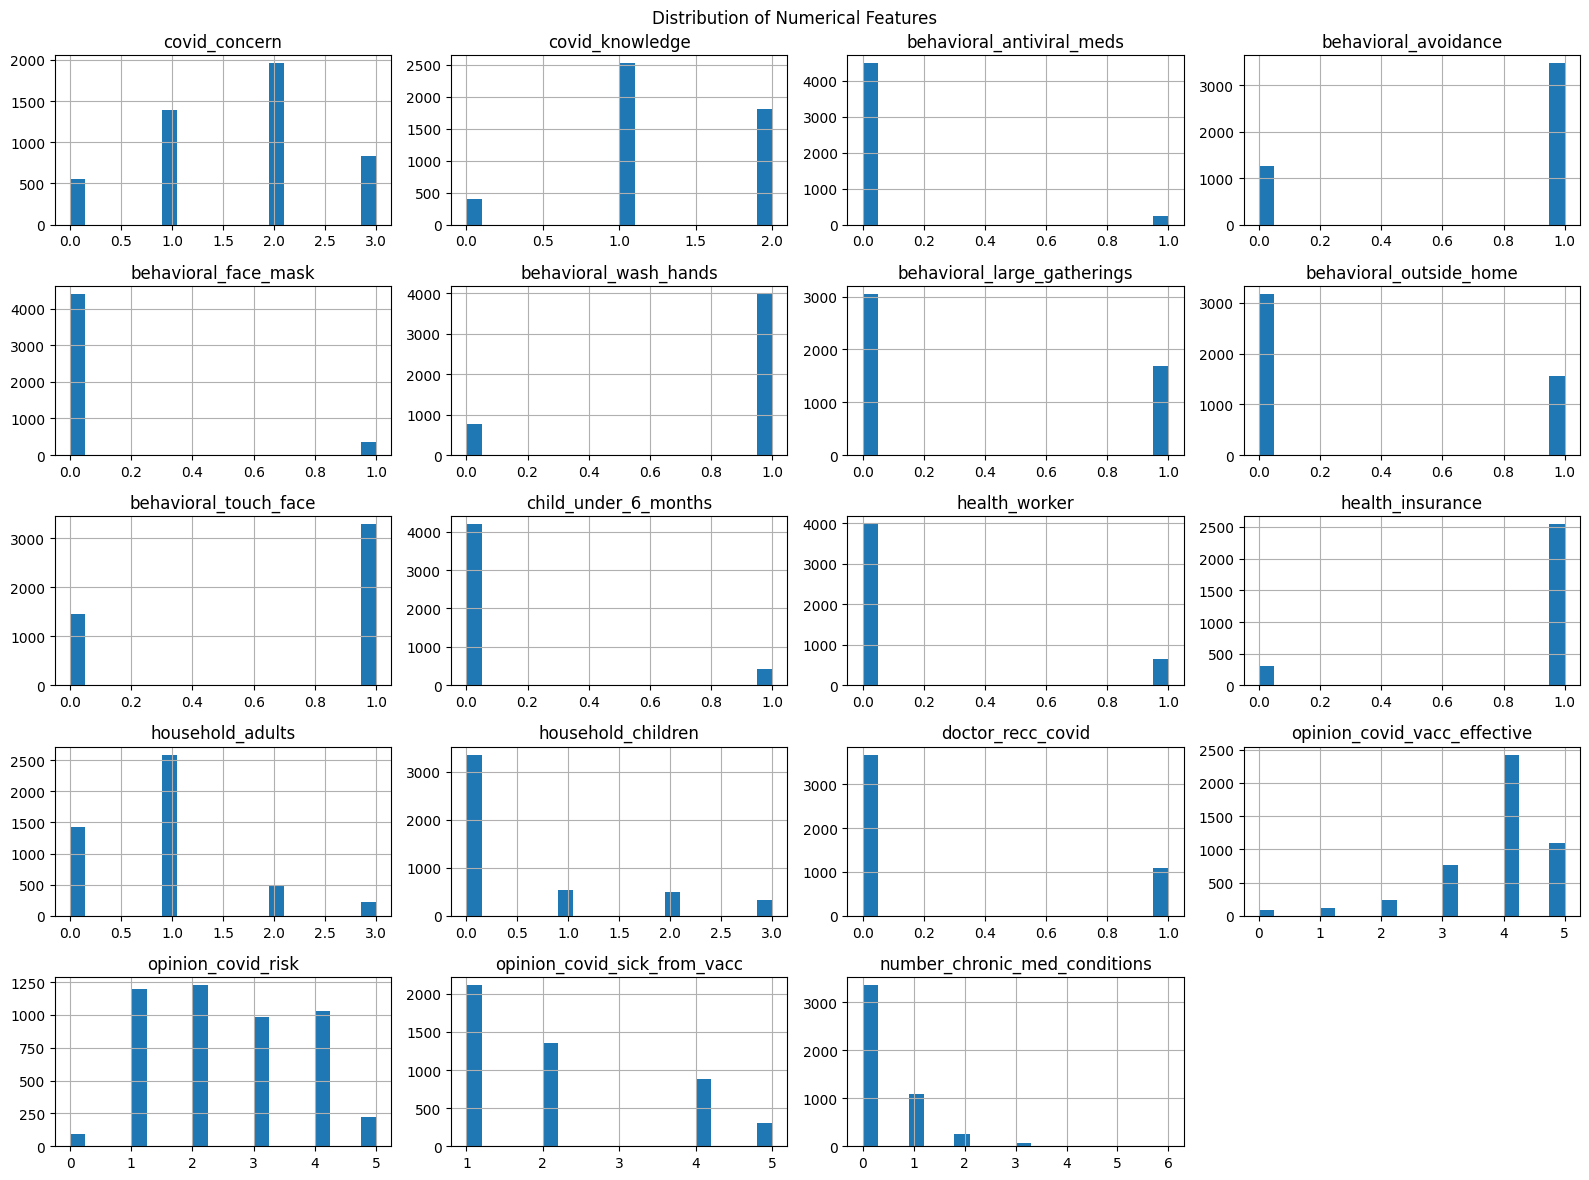

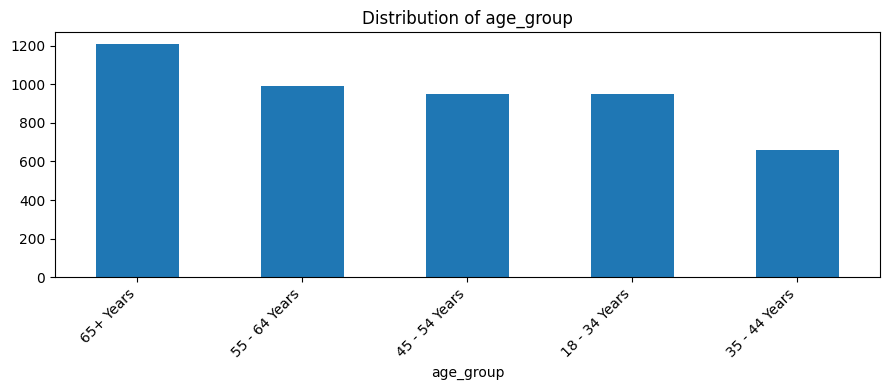

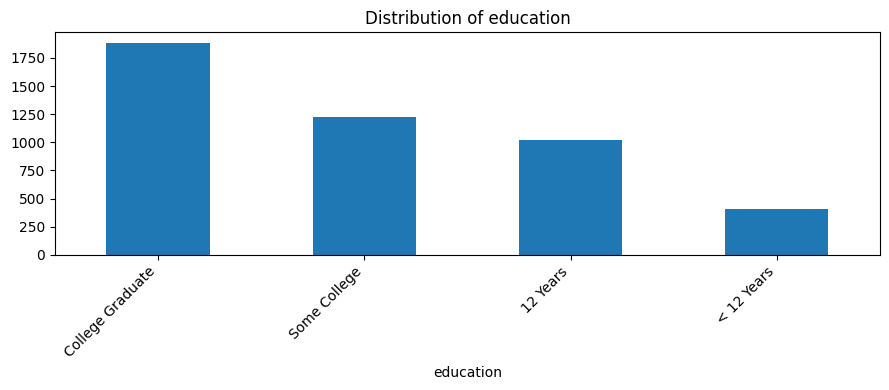

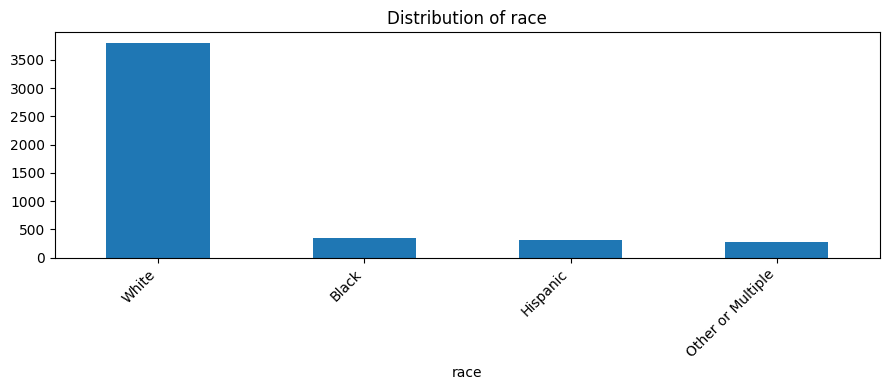

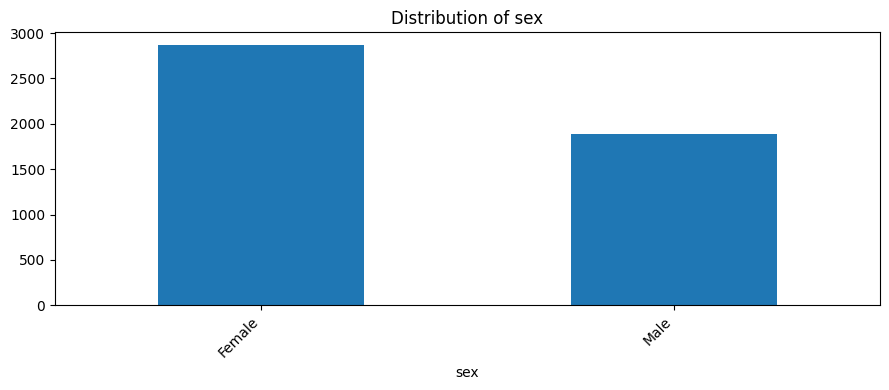

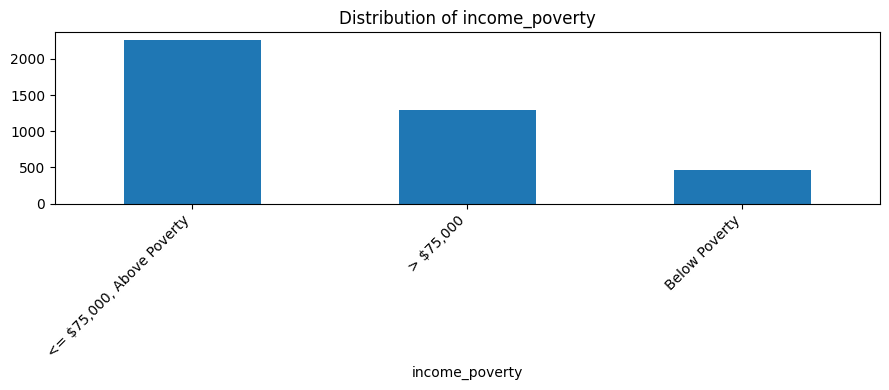

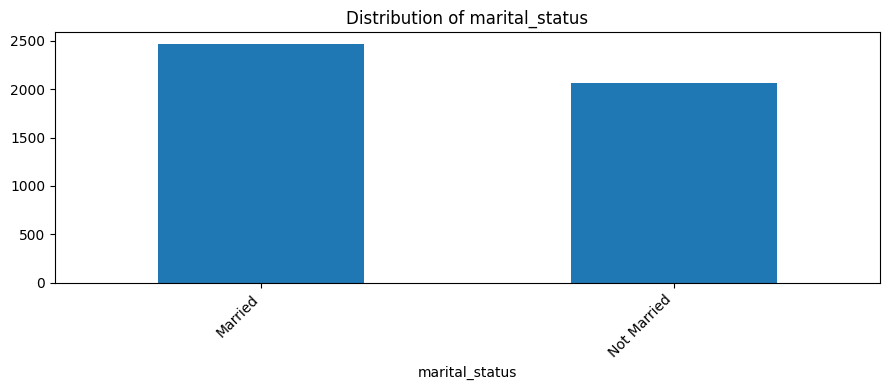

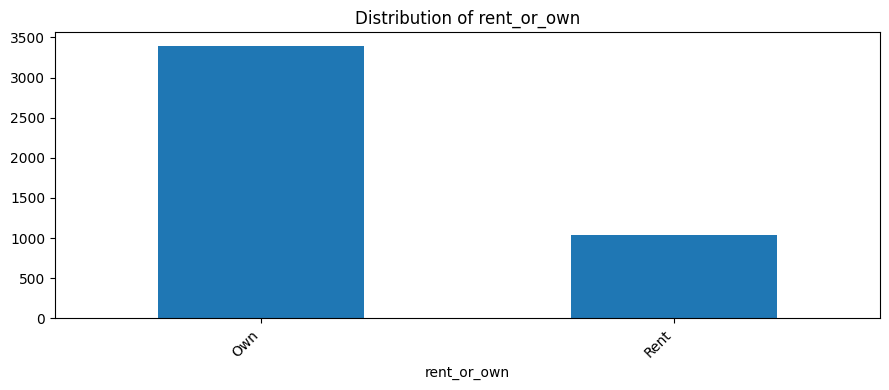

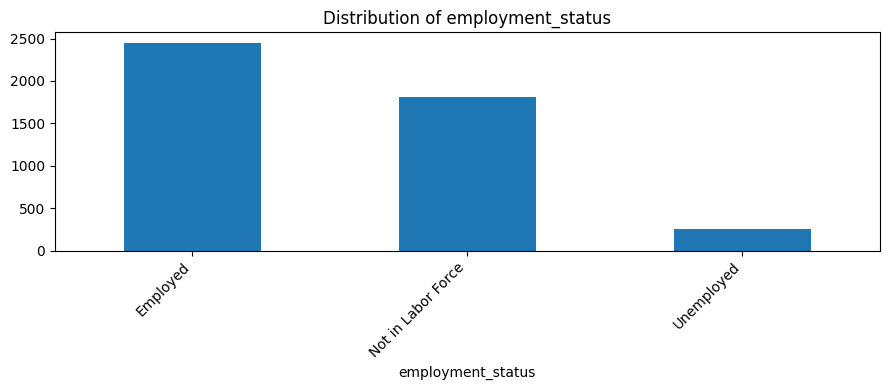

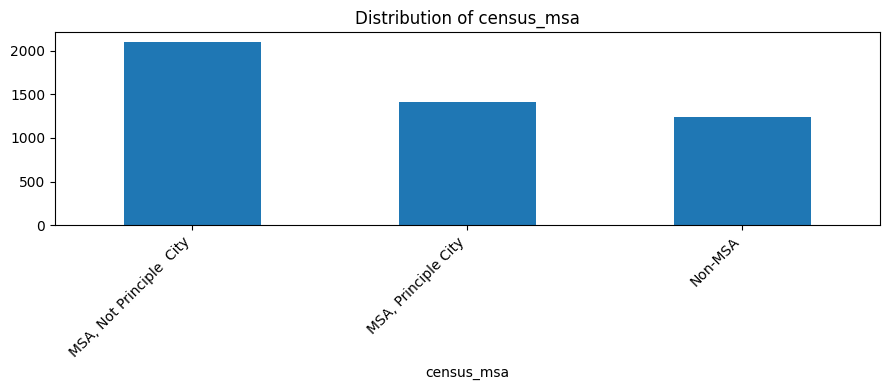

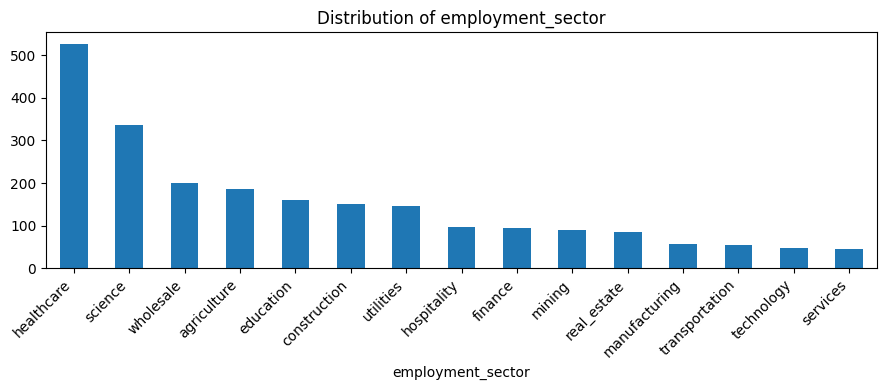

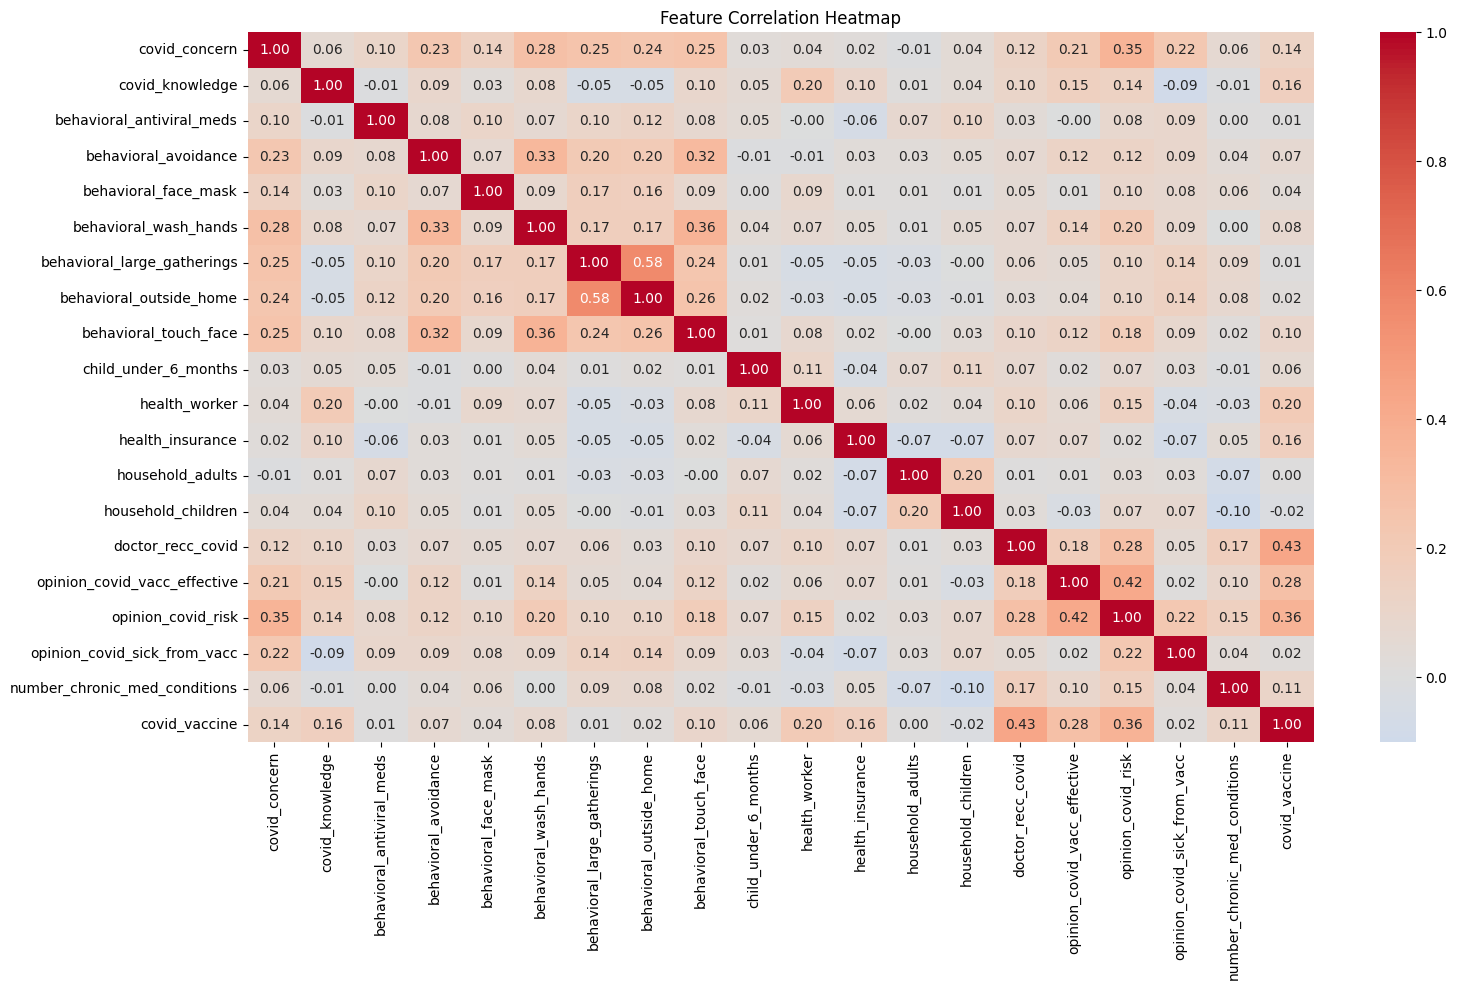

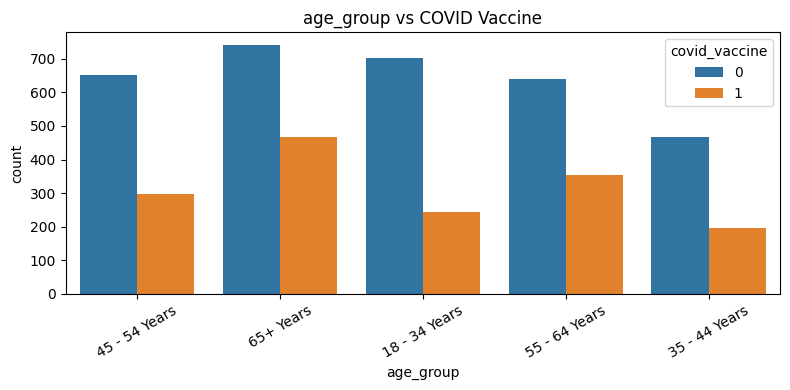

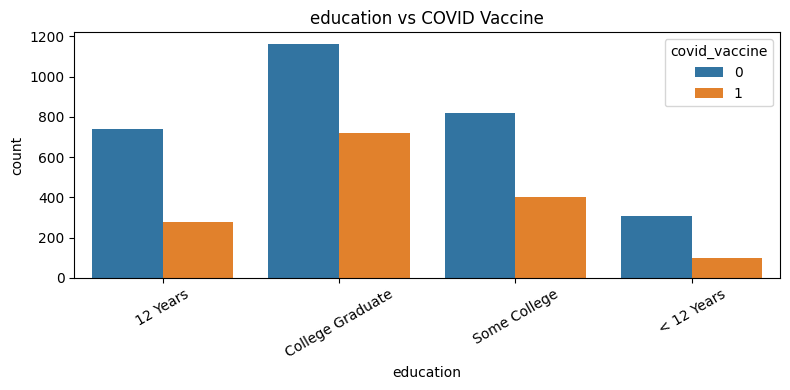

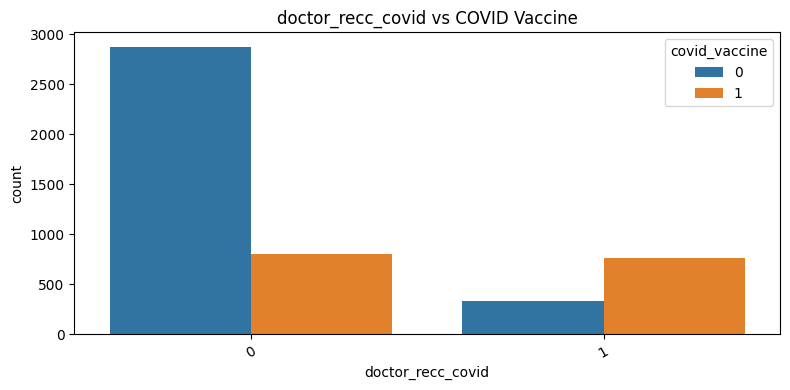

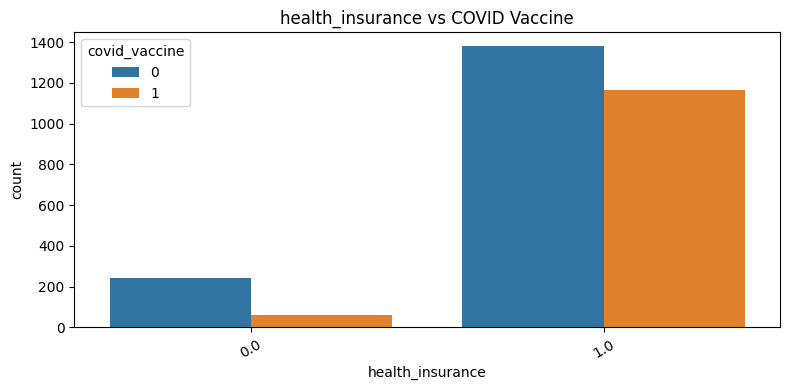

In [ ]:
# ==========================================
# 2. DATA EXPLORATION
# ==========================================

# Dataset information
print("TRAINING DATA INFORMATION")
train_df.info()

print("\nSTATISTICAL SUMMARY")
display(train_df.describe(include="all").T)

# Missing values
missing = pd.DataFrame({
    "Missing Count": train_df.isnull().sum(),
    "Missing Percentage":
        train_df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing Percentage", ascending=False
)

display(missing[missing["Missing Count"] > 0])

# Duplicate records
print("Duplicate rows:", train_df.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(train_df["covid_vaccine"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=train_df, x="covid_vaccine")
plt.title("COVID-19 Vaccine Distribution")
plt.xlabel("COVID Vaccine (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents")
plt.show()

# Target distribution percentage
print(train_df["covid_vaccine"].value_counts(normalize=True) * 100)

# Numerical features
numerical_cols = train_df.select_dtypes(
    include=np.number
).columns.drop(["respondent_id", "covid_vaccine"],
               errors="ignore")

train_df[numerical_cols].hist(
    figsize=(16, 12), bins=20
)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

# Categorical features
categorical_cols = train_df.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    plt.figure(figsize=(9, 4))
    train_df[col].value_counts().head(15).plot(
        kind="bar"
    )
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Correlation heatmap
plt.figure(figsize=(16, 10))

correlation = train_df.select_dtypes(
    include=np.number
).drop(columns=["respondent_id"], errors="ignore").corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# Relationship between selected features and target
for col in ["age_group", "education",
            "doctor_recc_covid", "health_insurance"]:

    plt.figure(figsize=(8, 4))
    sns.countplot(
        data=train_df,
        x=col,
        hue="covid_vaccine"
    )
    plt.title(f"{col} vs COVID Vaccine")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [6]:
# ==========================================
# 3. DATA PREPROCESSING
# ==========================================

# Remove duplicate rows
train_df = train_df.drop_duplicates().copy()

# Separate features and target
X = train_df.drop(
    columns=["covid_vaccine", "respondent_id"]
)

y = train_df["covid_vaccine"]

# Keep testing IDs separately
test_ids = test_df["respondent_id"].copy()

# Remove ID from test features
X_test = test_df.drop(
    columns=["respondent_id"]
)

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer,
         numerical_features),

        ("cat", categorical_transformer,
         categorical_features)
    ]
)

# Split training data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Validation samples:", X_val.shape)
print("Training completed successfully.")


Numerical features: ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']
Categorical features: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']
Training samples: (3804, 29)
Validation samples: (952, 29)
Training completed successfully.


In [8]:
# ==========================================
# 4. MODELLING
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipeline(model):
    return Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

# Model -> (estimator, hyper-parameter grid)
candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [8, 14, None],
         "model__min_samples_leaf": [1, 3, 8]}
    ),
    "Extra Trees": (
        ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [8, 14, None],
         "model__min_samples_leaf": [1, 3, 8]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200],
         "model__learning_rate": [0.05, 0.1],
         "model__max_depth": [2, 3]}
    ),
    "Support Vector Machine": (
        SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
        {"model__C": [0.3, 1, 3],
         "model__gamma": ["scale", 0.01]}
    ),
    "K-Nearest Neighbours": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [15, 31, 51],
         "model__weights": ["uniform", "distance"]}
    ),
    "AdaBoost": (
        AdaBoostClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200],
         "model__learning_rate": [0.3, 1.0]}
    ),
    "Neural Network (MLP)": (
        MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
        {"model__hidden_layer_sizes": [(32,), (64, 32)],
         "model__alpha": [0.001, 0.01, 0.1]}
    ),
}

# Baseline: always predicts the majority class
baseline = make_pipeline(DummyClassifier(strategy="most_frequent"))
baseline.fit(X_train, y_train)

best_models = {}
tuning_rows = []

for name, (estimator, grid) in candidates.items():
    search = GridSearchCV(
        make_pipeline(estimator), grid,
        scoring="roc_auc", cv=cv, n_jobs=-1
    )
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "CV ROC AUC": round(search.best_score_, 4),
        "Best parameters": search.best_params_
    })
    print(f"{name}: CV AUC = {search.best_score_:.4f}  {search.best_params_}")

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(tuning_rows).sort_values("CV ROC AUC", ascending=False))

Logistic Regression: CV AUC = 0.8276  {'model__C': 0.3}
Random Forest: CV AUC = 0.8349  {'model__max_depth': 8, 'model__min_samples_leaf': 3}
Extra Trees: CV AUC = 0.8285  {'model__max_depth': 8, 'model__min_samples_leaf': 1}
Gradient Boosting: CV AUC = 0.8388  {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
Support Vector Machine: CV AUC = 0.8274  {'model__C': 3, 'model__gamma': 0.01}
K-Nearest Neighbours: CV AUC = 0.8058  {'model__n_neighbors': 51, 'model__weights': 'distance'}
AdaBoost: CV AUC = 0.8341  {'model__learning_rate': 1.0, 'model__n_estimators': 200}
Neural Network (MLP): CV AUC = 0.8242  {'model__alpha': 0.1, 'model__hidden_layer_sizes': (32,)}


,Model,CV ROC AUC,Best parameters
3,Gradient Boosting,0.8388,"{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}"
1,Random Forest,0.8349,"{'model__max_depth': 8, 'model__min_samples_leaf': 3}"
6,AdaBoost,0.8341,"{'model__learning_rate': 1.0, 'model__n_estimators': 200}"
2,Extra Trees,0.8285,"{'model__max_depth': 8, 'model__min_samples_leaf': 1}"
0,Logistic Regression,0.8276,{'model__C': 0.3}
4,Support Vector Machine,0.8274,"{'model__C': 3, 'model__gamma': 0.01}"
7,Neural Network (MLP),0.8242,"{'model__alpha': 0.1, 'model__hidden_layer_sizes': (32,)}"
5,K-Nearest Neighbours,0.8058,"{'model__n_neighbors': 51, 'model__weights': 'distance'}"


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Gradient Boosting,0.7920,0.7446,0.5531,0.6347,0.8357
Random Forest,0.7794,0.7672,0.4662,0.5800,0.8333
AdaBoost,0.8015,0.7563,0.5788,0.6557,0.8326
Extra Trees,0.7784,0.7747,0.4534,0.5720,0.8307
Logistic Regression,0.7973,0.7458,0.5756,0.6497,0.8267
Support Vector Machine,0.7836,0.7273,0.5402,0.6199,0.8216
Neural Network (MLP),0.7962,0.7407,0.5788,0.6498,0.8201
K-Nearest Neighbours,0.7721,0.7701,0.4309,0.5526,0.8147
Dummy baseline,0.6733,0.0000,0.0000,0.0000,0.5000


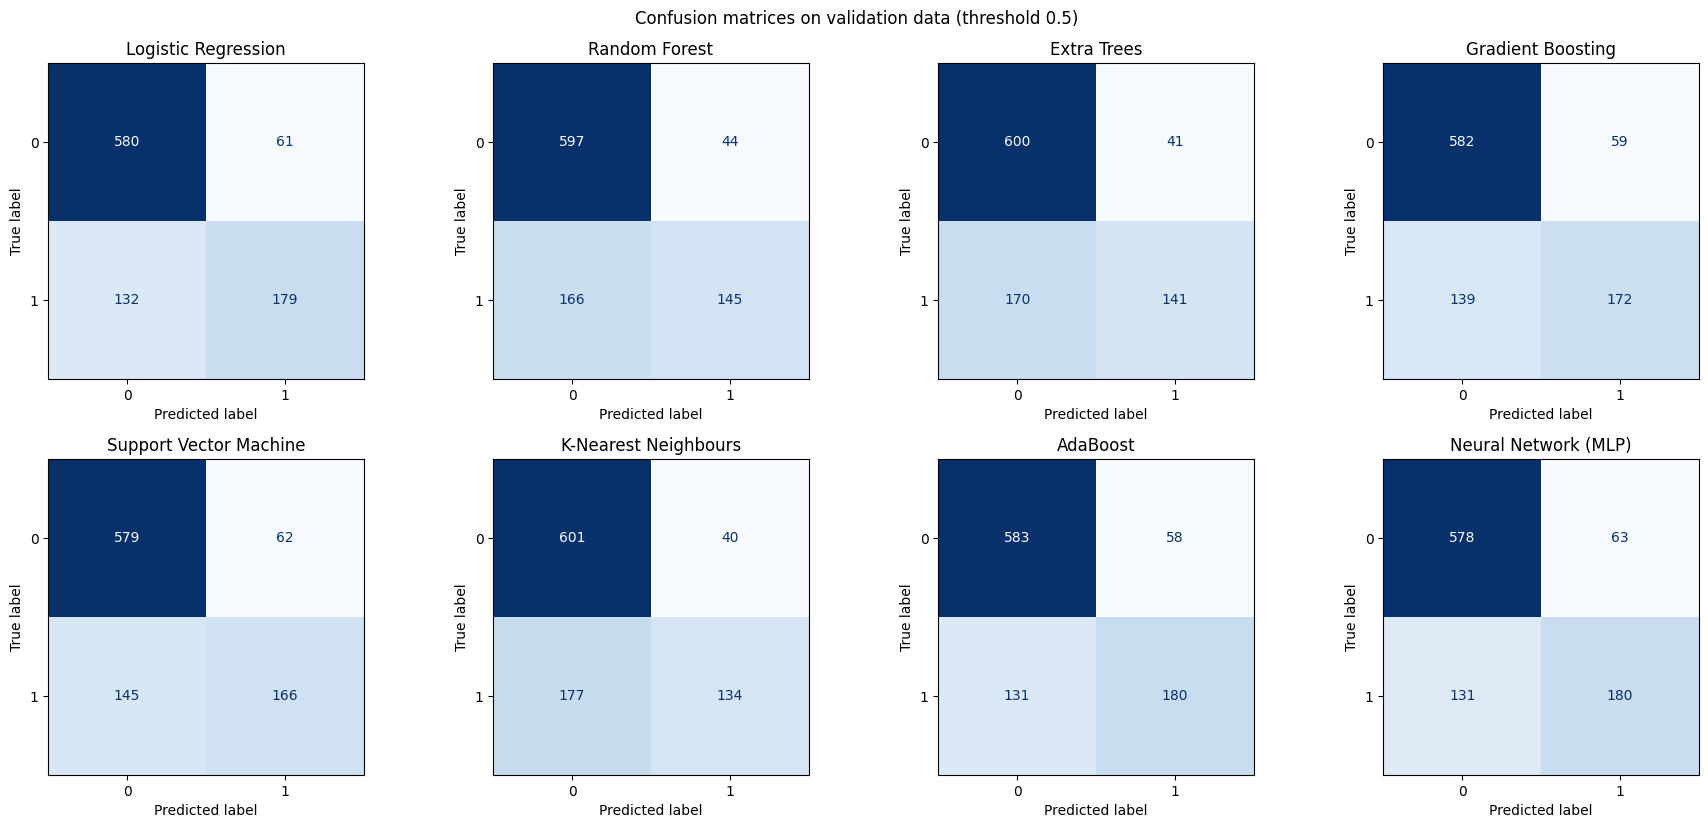

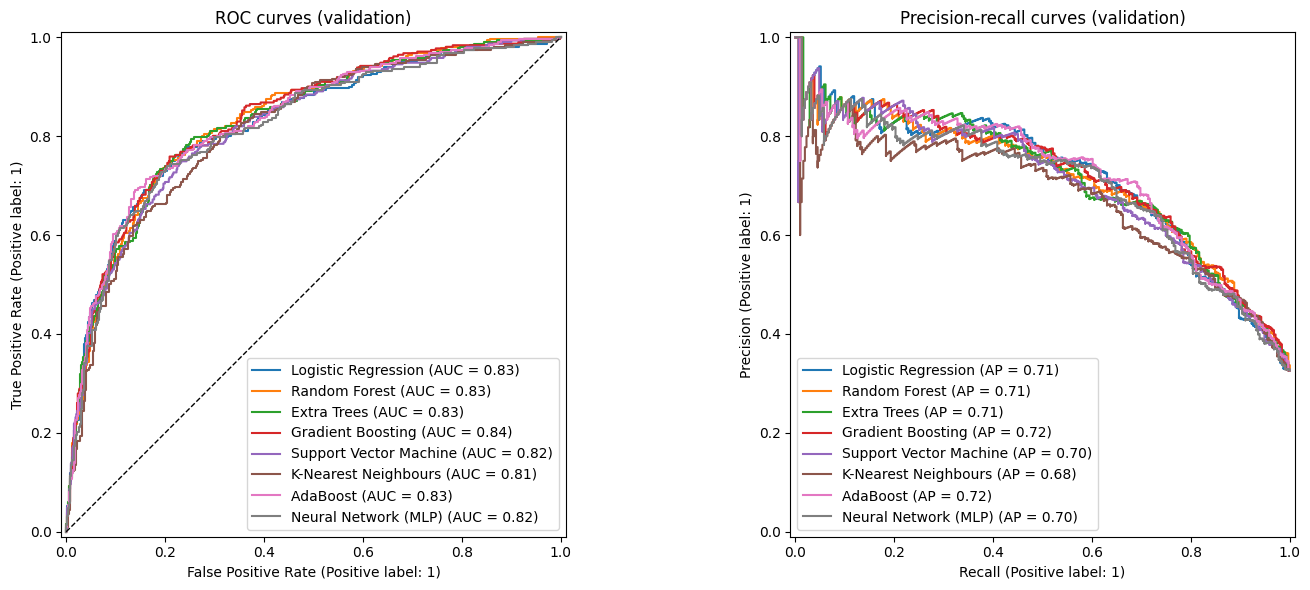

Classification report: Gradient Boosting
              precision    recall  f1-score   support

           0       0.81      0.91      0.85       641
           1       0.74      0.55      0.63       311

    accuracy                           0.79       952
   macro avg       0.78      0.73      0.74       952
weighted avg       0.79      0.79      0.78       952



In [9]:
# ==========================================
# 5. PERFORMANCE ANALYSIS
# ==========================================

def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC AUC": roc_auc_score(y_eval, proba),
    }

results = [evaluate("Dummy baseline", baseline, X_val, y_val)]
for name, model in best_models.items():
    results.append(evaluate(name, model, X_val, y_val))

results_df = (pd.DataFrame(results)
              .set_index("Model")
              .sort_values("ROC AUC", ascending=False)
              .round(4))
display(results_df)

# Confusion matrices
n_cols = 4
n_rows = int(np.ceil(len(best_models) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.2 * n_rows))
for ax in axes.ravel()[len(best_models):]:
    ax.axis("off")
for ax, (name, model) in zip(axes.ravel(), best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_val, y_val, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
plt.suptitle("Confusion matrices on validation data (threshold 0.5)")
plt.tight_layout()
plt.show()

# ROC and precision-recall curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(15, 6))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_val, y_val, ax=ax_roc, name=name)
    PrecisionRecallDisplay.from_estimator(model, X_val, y_val, ax=ax_pr, name=name)
ax_roc.plot([0, 1], [0, 1], "k--", linewidth=1)
ax_roc.set_title("ROC curves (validation)")
ax_pr.set_title("Precision-recall curves (validation)")
plt.tight_layout()
plt.show()

# Classification report for the best model by AUC
best_name = results_df.drop(index="Dummy baseline")["ROC AUC"].idxmax()
print(f"Classification report: {best_name}")
print(classification_report(y_val, best_models[best_name].predict(X_val)))